# 01 · 探索性数据分析（EDA）

**数据集**：Global AI Jobs Report 2026 —— 5000 条全球 AI 岗位记录 × 37 个字段

**分析主题**（8 项）：

1. Most common AI job roles —— 最常见的 AI 岗位
2. Salary distributions —— 薪资分布
3. Experience distributions —— 经验分布
4. Geographic trends —— 地理趋势
5. Industry patterns —— 行业模式
6. Remote-work trends —— 远程办公趋势
7. Automation-risk distributions —— 自动化风险分布
8. Job satisfaction patterns —— 工作满意度模式

> 所有聚合均采用 pandas 管道式操作（`groupby / agg / query / assign / sort_values`）完成。

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scripts.common import (
    load_data, setup_style, fmt_usd, insights,
    EDU_ORDER, EXP_ORDER, SALARY_CAT_ORDER, RENAME_MAP,
)

setup_style()
df = load_data()
print(f"数据规模: {df.shape[0]} 行 × {df.shape[1]} 列")
df.head(3)

数据规模: 5000 行 × 40 列


,job_id,job_title,ai_specialization,industry,company,company_size,country,continent,education,experience_level,...,growth_pct,automation_risk_pct,female_pct,posted_date,deadline,record_created,source,skill_count,salary_range,is_remote_friendly
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026,6,302481,1
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026,6,193179,0
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026,6,372316,1


In [2]:
# 列名规范化映射（原始列 -> 简洁列名）
pd.Series(RENAME_MAP).to_frame("新列名").head(40)

,新列名
Job_ID,job_id
Job_Title,job_title
AI_Specialization,ai_specialization
Industry,industry
Company,company
Company_Size,company_size
Country,country
Continent,continent
Education_Required,education
Experience_Level,experience_level


In [3]:
# 数据质量概览
print(f"Job_ID 重复数: {df['job_id'].duplicated().sum()}")
miss = df.isna().sum()
print("缺失值:")
print(miss[miss > 0] if miss.sum() else "  无缺失")

df.select_dtypes("number").describe().T.round(2)

Job_ID 重复数: 0
缺失值:
certifications    840
dtype: int64


,count,mean,std,min,25%,50%,75%,max
years_experience,5000.0,7.58,6.25,0.0,2.00,7.00,12.00,20.0
salary_usd,5000.0,158179.96,78886.44,27934.0,104261.25,141886.00,191695.00,718357.0
salary_min,5000.0,126656.83,63920.02,21398.0,83105.50,113983.00,154688.50,614788.0
salary_max,5000.0,197920.71,100139.16,34852.0,129468.00,176796.00,239955.75,917269.0
bonus_pct,5000.0,17.34,7.24,5.0,10.90,17.40,23.60,30.0
benefits_usd,5000.0,22363.50,10110.62,5002.0,13607.75,22412.00,31134.25,39989.0
job_openings,5000.0,10.07,3.21,1.0,8.00,10.00,12.00,22.0
applicants,5000.0,257.90,141.56,10.0,134.00,259.00,381.00,500.0
hiring_difficulty,5000.0,6.30,1.88,3.0,4.70,6.30,7.90,9.5
remote_pct,5000.0,57.75,26.12,0.0,40.00,60.00,80.00,100.0


## 1. Most common AI job roles —— 最常见的 AI 岗位

**管道**：`groupby(job_title).agg(...)` 统计岗位数量与薪资水平；`value_counts` 统计专业方向。

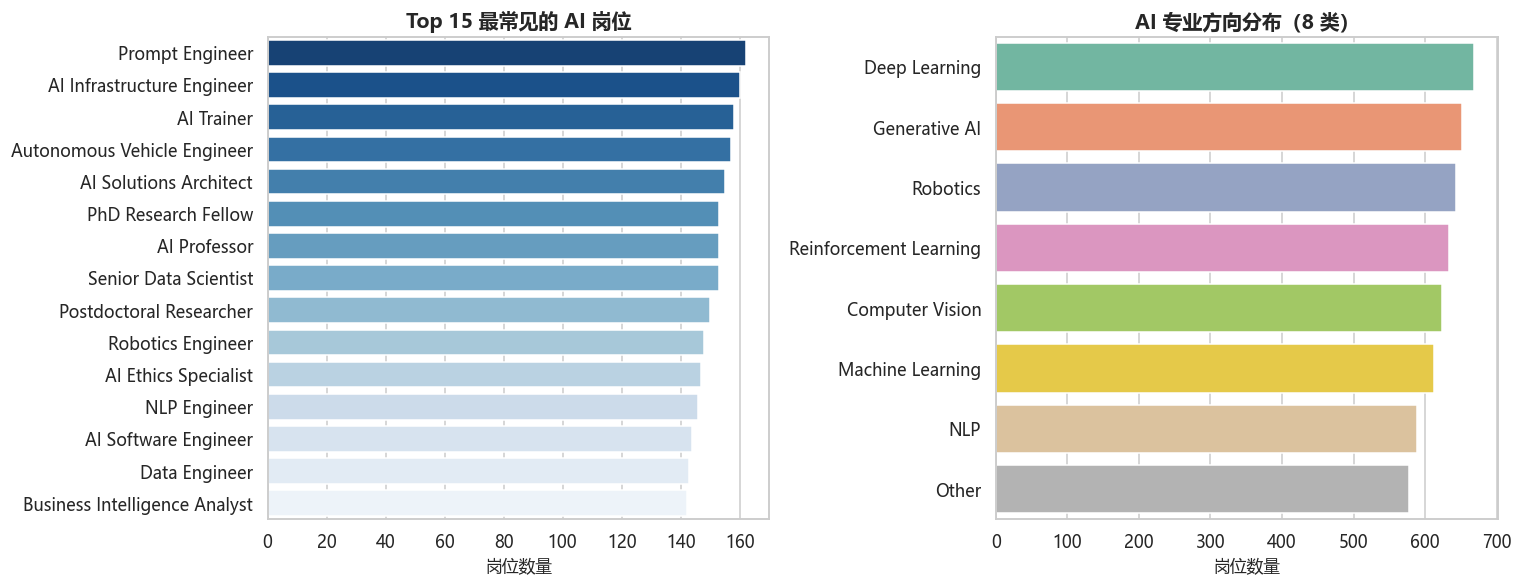

· 岗位数量最多：Prompt Engineer（162 个，占 3.2%）
· 36 类岗位数量高度均衡（106~162 个），Top 10 合计仅占 31.0%，无明显长尾
· 专业方向覆盖 8 类，最多为 Deep Learning（668 个），分布同样均衡


In [4]:
# 管道：按岗位聚合 -> 排序 -> 取 Top 15
roles = (
    df.groupby("job_title")
      .agg(jobs=("job_id", "count"),
           median_salary=("salary_usd", "median"),
           avg_openings=("job_openings", "mean"))
      .sort_values("jobs", ascending=False)
)
top_roles = roles.head(15)
spec_counts = df["ai_specialization"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(x=top_roles["jobs"], y=top_roles.index, hue=top_roles.index,
            palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("Top 15 最常见的 AI 岗位")
axes[0].set_xlabel("岗位数量"); axes[0].set_ylabel("")

sns.barplot(x=spec_counts.values, y=spec_counts.index, hue=spec_counts.index,
            palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("AI 专业方向分布（8 类）")
axes[1].set_xlabel("岗位数量"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

insights(
    f"岗位数量最多：{roles.index[0]}（{roles['jobs'].iloc[0]} 个，占 {roles['jobs'].iloc[0] / len(df):.1%}）",
    f"36 类岗位数量高度均衡（{roles['jobs'].min()}~{roles['jobs'].max()} 个），Top 10 合计仅占 {roles['jobs'].head(10).sum() / len(df):.1%}，无明显长尾",
    f"专业方向覆盖 8 类，最多为 {spec_counts.index[0]}（{spec_counts.iloc[0]} 个），分布同样均衡",
)

## 2. Salary distributions —— 薪资分布

**管道**：`agg` 计算薪资统计量；`groupby(experience_level)` 按经验等级分组观察薪资形态。

mean      158180.0
median    141886.0
std        78886.0
min        27934.0
max       718357.0


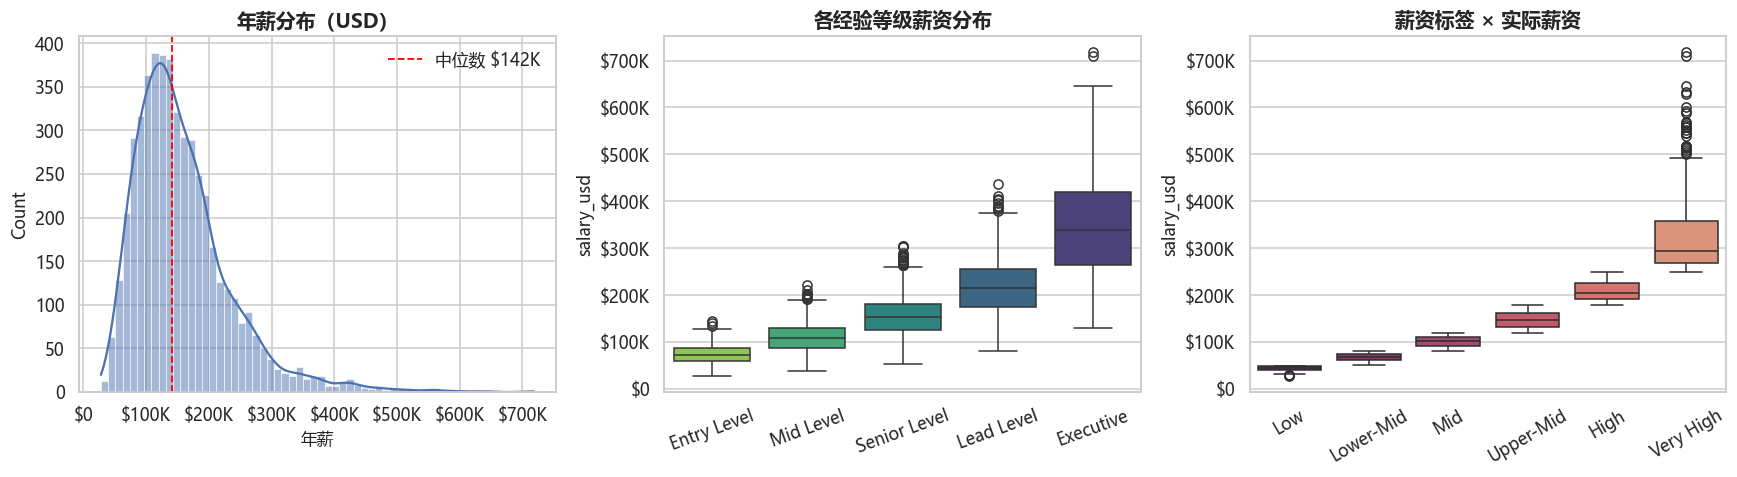

· 均值 $158K 高于中位数 $142K，偏度 1.69，分布明显右偏
· 主体区间 $104K ~ $192K（IQR），最高薪 $718K 为长尾离群值
· 薪资标签（Low~Very High）与实际薪资单调对应，标签由薪资分位数划分而来


In [5]:
sal = df["salary_usd"]
stats = sal.agg(["mean", "median", "std", "min", "max"])
print(stats.round(0).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(sal, bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(sal.median(), color="red", ls="--", lw=1.2,
                label=f"中位数 {fmt_usd(sal.median())}")
axes[0].xaxis.set_major_formatter(fmt_usd)
axes[0].set_title("年薪分布（USD）"); axes[0].set_xlabel("年薪"); axes[0].legend()

sns.boxplot(data=df, x="experience_level", y="salary_usd", order=EXP_ORDER,
            hue="experience_level", palette="viridis", legend=False, ax=axes[1])
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("各经验等级薪资分布"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="salary_category", y="salary_usd", order=SALARY_CAT_ORDER,
            hue="salary_category", palette="flare", legend=False, ax=axes[2])
axes[2].yaxis.set_major_formatter(fmt_usd)
axes[2].set_title("薪资标签 × 实际薪资"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout(); plt.show()

insights(
    f"均值 {fmt_usd(stats['mean'])} 高于中位数 {fmt_usd(stats['median'])}，偏度 {sal.skew():.2f}，分布明显右偏",
    f"主体区间 {fmt_usd(sal.quantile(0.25))} ~ {fmt_usd(sal.quantile(0.75))}（IQR），最高薪 {fmt_usd(stats['max'])} 为长尾离群值",
    f"薪资标签（Low~Very High）与实际薪资单调对应，标签由薪资分位数划分而来",
)

## 3. Experience distributions —— 经验分布

**管道**：`value_counts` 统计经验等级；`groupby(experience_level)` 观察各等级对应的实际年限。

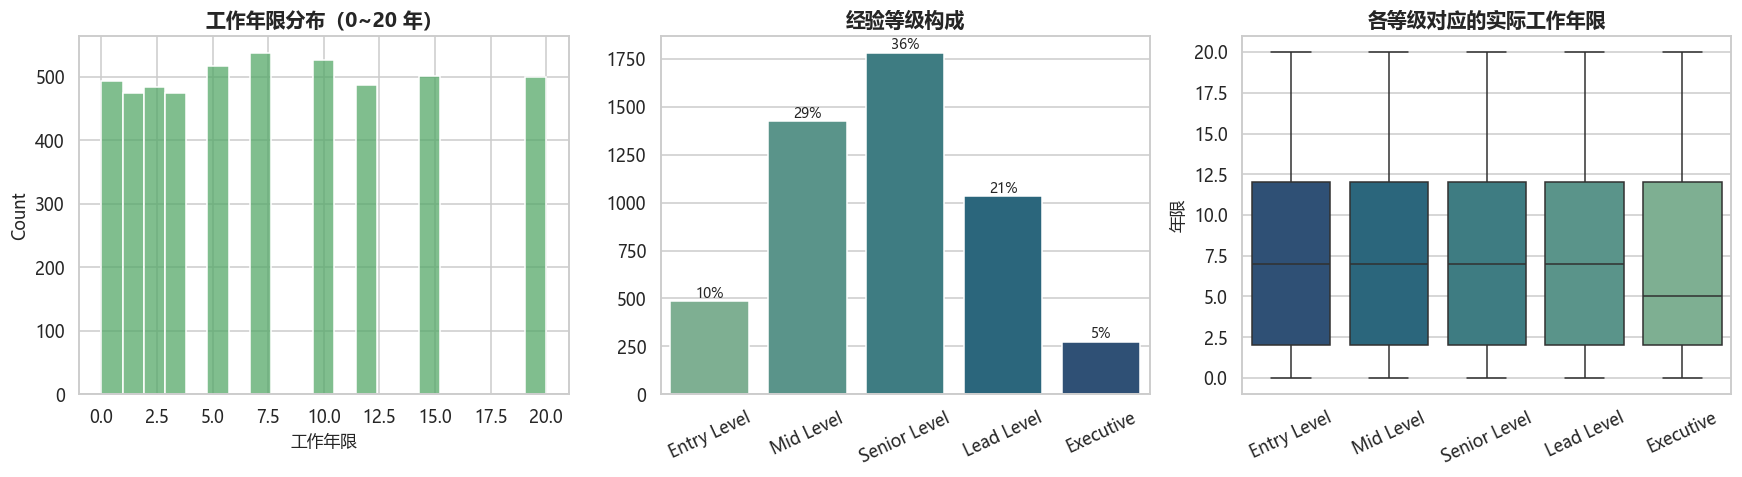

· 年限均匀覆盖 0~20 年（均值 7.6 年），无明显集聚
· 经验等级构成：Senior 35.6% > Mid 28.5% > Lead 20.7% > Entry 9.7% > Executive 5.5%，中高级岗位为主体
· 注意：各等级年限箱体高度重叠（如 Executive 也有 0~2 年样本），等级与年限的一致性较弱，属数据源特征


In [6]:
exp_counts = df["experience_level"].value_counts().reindex(EXP_ORDER)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df, x="years_experience", bins=21, ax=axes[0], color="#55A868")
axes[0].set_title("工作年限分布（0~20 年）"); axes[0].set_xlabel("工作年限")

sns.barplot(x=exp_counts.index, y=exp_counts.values, hue=exp_counts.index,
            palette="crest", legend=False, ax=axes[1])
axes[1].set_title("经验等级构成"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=25)
for i, v in enumerate(exp_counts.values):
    axes[1].text(i, v + 20, f"{v / len(df):.0%}", ha="center", fontsize=9)

sns.boxplot(data=df, x="experience_level", y="years_experience", order=EXP_ORDER,
            hue="experience_level", palette="crest", legend=False, ax=axes[2])
axes[2].set_title("各等级对应的实际工作年限"); axes[2].set_xlabel(""); axes[2].set_ylabel("年限")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout(); plt.show()

insights(
    f"年限均匀覆盖 0~20 年（均值 {df['years_experience'].mean():.1f} 年），无明显集聚",
    "经验等级构成：Senior 35.6% > Mid 28.5% > Lead 20.7% > Entry 9.7% > Executive 5.5%，中高级岗位为主体",
    "注意：各等级年限箱体高度重叠（如 Executive 也有 0~2 年样本），等级与年限的一致性较弱，属数据源特征",
)

## 4. Geographic trends —— 地理趋势

**管道**：`groupby(continent)` 聚合大洲岗位数与薪资中位数；`value_counts` 提取岗位最多的国家。

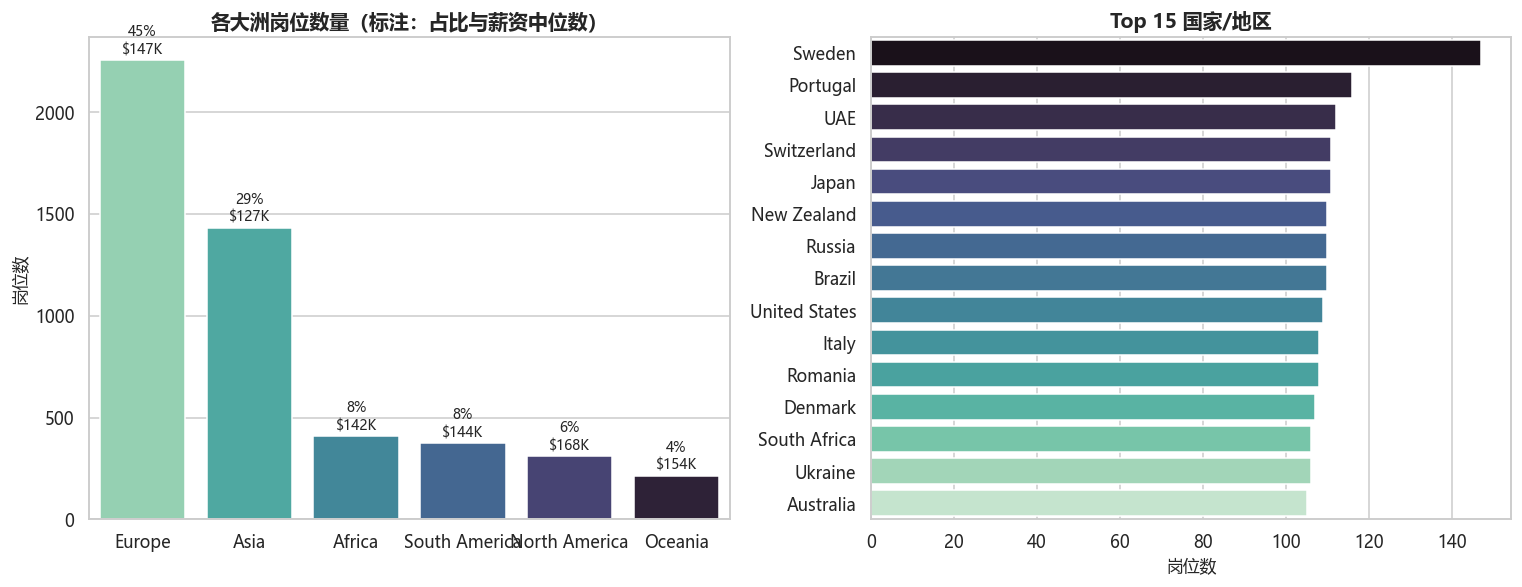

· 欧洲占 45.2%、亚洲占 28.7%，两大洲合计约 82%，是 AI 岗位的主要聚集地
· 北美仅 6.2%，但薪资中位数 $168K 居各洲第 1 位
· 岗位分散于 50 个国家，最多的 Sweden 也仅 147 个（2.9%），全球分布相当均衡


In [7]:
geo = (
    df.groupby("continent")
      .agg(jobs=("job_id", "count"), median_salary=("salary_usd", "median"))
      .sort_values("jobs", ascending=False)
)
top_countries = df["country"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(x=geo.index, y=geo["jobs"], hue=geo.index, palette="mako_r", legend=False, ax=axes[0])
for i, (cnt, sal) in enumerate(zip(geo["jobs"], geo["median_salary"])):
    axes[0].text(i, cnt + 30, f"{cnt / len(df):.0%}\n{fmt_usd(sal)}", ha="center", fontsize=9)
axes[0].set_title("各大洲岗位数量（标注：占比与薪资中位数）"); axes[0].set_xlabel(""); axes[0].set_ylabel("岗位数")

sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette="mako", legend=False, ax=axes[1])
axes[1].set_title("Top 15 国家/地区"); axes[1].set_xlabel("岗位数"); axes[1].set_ylabel("")

plt.tight_layout(); plt.show()

na_rank = geo["median_salary"].rank(ascending=False)["North America"]
insights(
    f"欧洲占 {geo.loc['Europe', 'jobs'] / len(df):.1%}、亚洲占 {geo.loc['Asia', 'jobs'] / len(df):.1%}，两大洲合计约 {1 - geo['jobs'].tail(3).sum() / len(df):.0%}，是 AI 岗位的主要聚集地",
    f"北美仅 {geo.loc['North America', 'jobs'] / len(df):.1%}，但薪资中位数 {fmt_usd(geo.loc['North America', 'median_salary'])} 居各洲第 {int(na_rank)} 位",
    f"岗位分散于 50 个国家，最多的 {top_countries.index[0]} 也仅 {top_countries.iloc[0]} 个（{top_countries.iloc[0] / len(df):.1%}），全球分布相当均衡",
)

## 5. Industry patterns —— 行业模式

**管道**：`groupby(industry).agg` 聚合岗位数、薪资、自动化风险与增长预期，观察行业间差异。

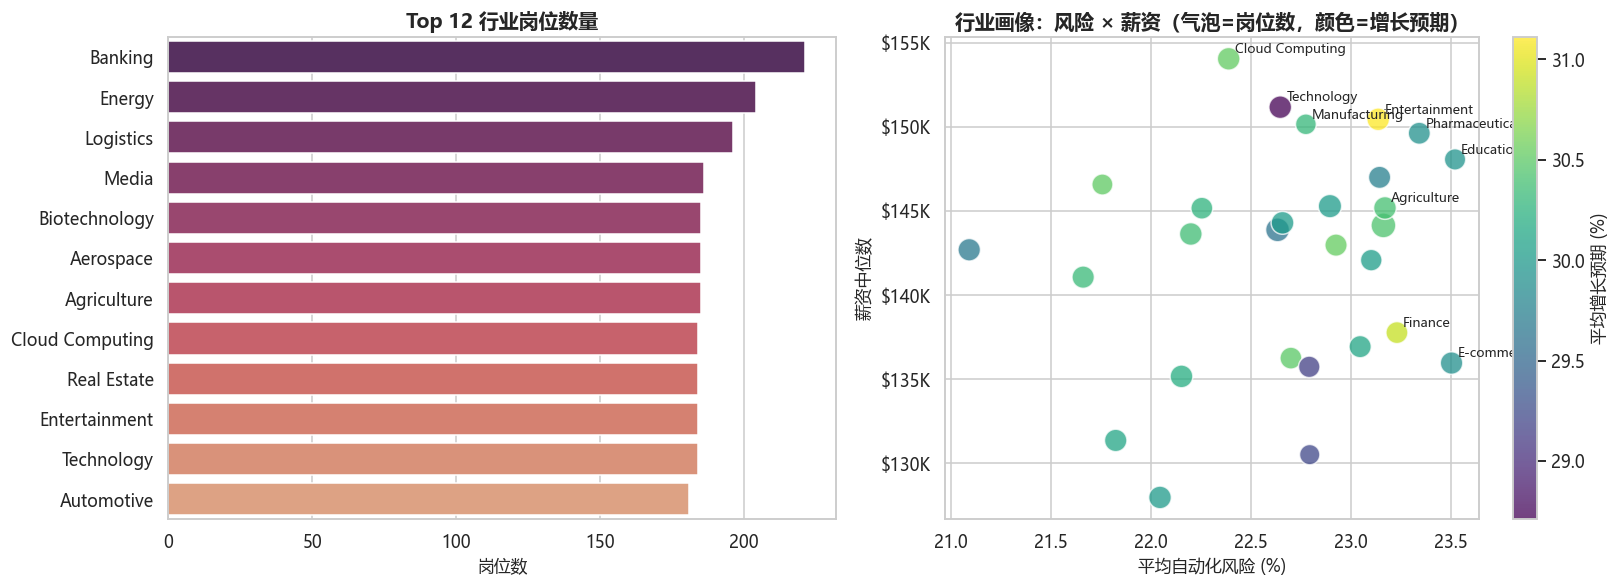

· 覆盖 28 个行业、数量均衡（148~221 个），Banking 略领先（221 个）
· 薪资中位数最高行业：Cloud Computing（$154K）
· 自动化风险最高行业：Education（23.5%），但整体差异不大，行业间风险梯度平缓


In [8]:
industry = (
    df.groupby("industry")
      .agg(jobs=("job_id", "count"),
           median_salary=("salary_usd", "median"),
           avg_risk=("automation_risk_pct", "mean"),
           avg_growth=("growth_pct", "mean"))
      .sort_values("jobs", ascending=False)
)
top_ind = industry.head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(x=top_ind["jobs"], y=top_ind.index, hue=top_ind.index,
            palette="flare_r", legend=False, ax=axes[0])
axes[0].set_title("Top 12 行业岗位数量"); axes[0].set_xlabel("岗位数"); axes[0].set_ylabel("")

sc = axes[1].scatter(industry["avg_risk"], industry["median_salary"],
                     s=industry["jobs"] * 1.2, c=industry["avg_growth"],
                     cmap="viridis", alpha=0.75, edgecolor="white")
for name, row in industry.iterrows():
    if row["median_salary"] > industry["median_salary"].quantile(0.85) or        row["avg_risk"] > industry["avg_risk"].quantile(0.85):
        axes[1].annotate(name, (row["avg_risk"], row["median_salary"]),
                         fontsize=8.5, xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("平均自动化风险 (%)"); axes[1].set_ylabel("薪资中位数")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("行业画像：风险 × 薪资（气泡=岗位数，颜色=增长预期）")
plt.colorbar(sc, ax=axes[1], label="平均增长预期 (%)")

plt.tight_layout(); plt.show()

hi_sal = industry["median_salary"].idxmax()
hi_risk = industry["avg_risk"].idxmax()
insights(
    f"覆盖 28 个行业、数量均衡（{industry['jobs'].min()}~{industry['jobs'].max()} 个），Banking 略领先（{industry['jobs'].max()} 个）",
    f"薪资中位数最高行业：{hi_sal}（{fmt_usd(industry.loc[hi_sal, 'median_salary'])}）",
    f"自动化风险最高行业：{hi_risk}（{industry.loc[hi_risk, 'avg_risk']:.1f}%），但整体差异不大，行业间风险梯度平缓",
)

## 6. Remote-work trends —— 远程办公趋势

**管道**：`groupby(job_type / industry)` 聚合平均远程比例与 WFH 支持率。

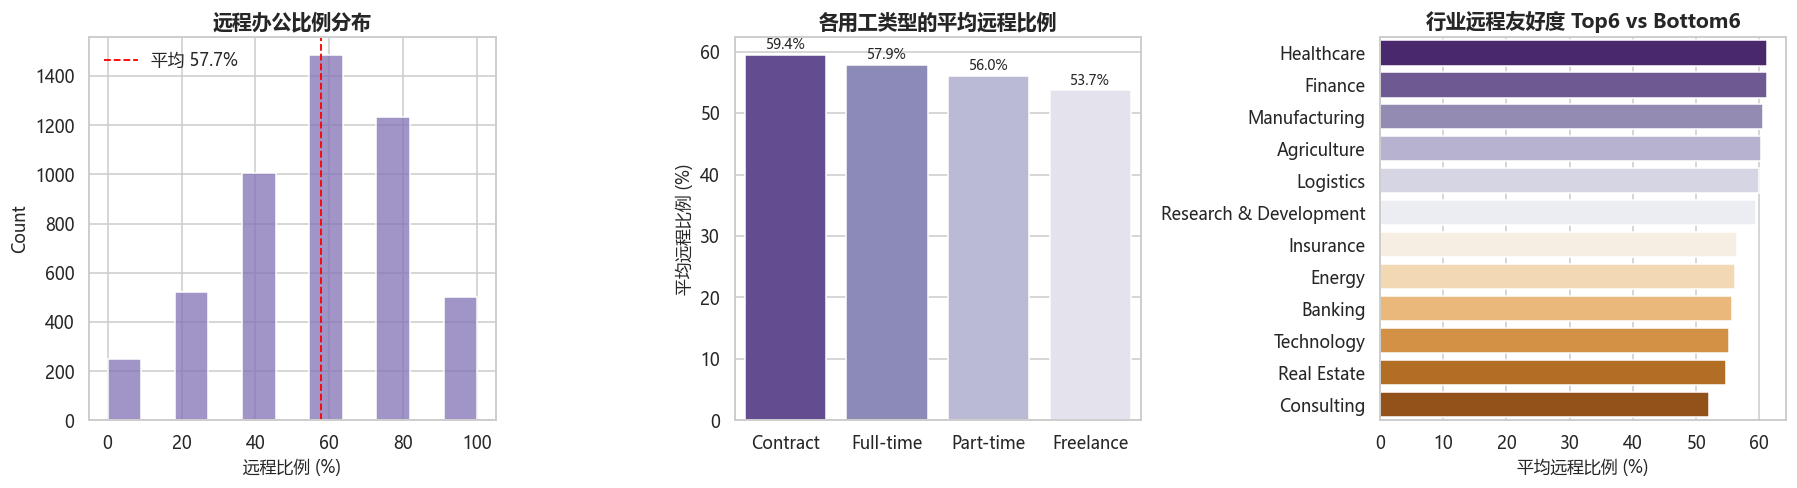

· 平均远程比例 57.7%，64.4% 的岗位明确支持居家办公（WFH）
· 用工类型差异不大：Freelance 53.7% vs Part-time 56.0%
· 行业间远程友好度梯度平缓：最高 Healthcare（61.2%）与最低 Consulting（52.0%）仅相差约 9 个百分点


In [9]:
by_type = (
    df.groupby("job_type")
      .agg(avg_remote=("remote_pct", "mean"),
           wfh_rate=("wfh", lambda s: s.eq("Yes").mean()),
           jobs=("job_id", "count"))
      .sort_values("avg_remote", ascending=False)
)
by_industry = (
    df.groupby("industry")
      .agg(avg_remote=("remote_pct", "mean"), wfh_rate=("wfh", lambda s: s.eq("Yes").mean()))
      .sort_values("avg_remote", ascending=False)
)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

sns.histplot(df, x="remote_pct", bins=11, ax=axes[0], color="#8172B3")
axes[0].axvline(df["remote_pct"].mean(), color="red", ls="--", lw=1.2,
                label=f"平均 {df['remote_pct'].mean():.1f}%")
axes[0].set_title("远程办公比例分布"); axes[0].set_xlabel("远程比例 (%)"); axes[0].legend()

sns.barplot(x=by_type.index, y=by_type["avg_remote"], hue=by_type.index,
            palette="Purples_r", legend=False, ax=axes[1])
for i, v in enumerate(by_type["avg_remote"]):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
axes[1].set_title("各用工类型的平均远程比例"); axes[1].set_xlabel(""); axes[1].set_ylabel("平均远程比例 (%)")

sub = pd.concat([by_industry.head(6), by_industry.tail(6)])
sns.barplot(x=sub["avg_remote"], y=sub.index, hue=sub.index, palette="PuOr_r", legend=False, ax=axes[2])
axes[2].set_title("行业远程友好度 Top6 vs Bottom6"); axes[2].set_xlabel("平均远程比例 (%)"); axes[2].set_ylabel("")

plt.tight_layout(); plt.show()

wfh_ratio = df["wfh"].eq("Yes").mean()
insights(
    f"平均远程比例 {df['remote_pct'].mean():.1f}%，{wfh_ratio:.1%} 的岗位明确支持居家办公（WFH）",
    f"用工类型差异不大：Freelance {by_type.loc['Freelance', 'avg_remote']:.1f}% vs Part-time {by_type.loc['Part-time', 'avg_remote']:.1f}%",
    f"行业间远程友好度梯度平缓：最高 {by_industry.index[0]}（{by_industry.iloc[0, 0]:.1f}%）与最低 {by_industry.index[-1]}（{by_industry.iloc[-1, 0]:.1f}%）仅相差约 {by_industry.iloc[0, 0] - by_industry.iloc[-1, 0]:.0f} 个百分点",
)

## 7. Automation-risk distributions —— 自动化风险分布

**管道**：`groupby(job_title)` 计算各岗位平均自动化风险，取最高/最低各 10 名对比。

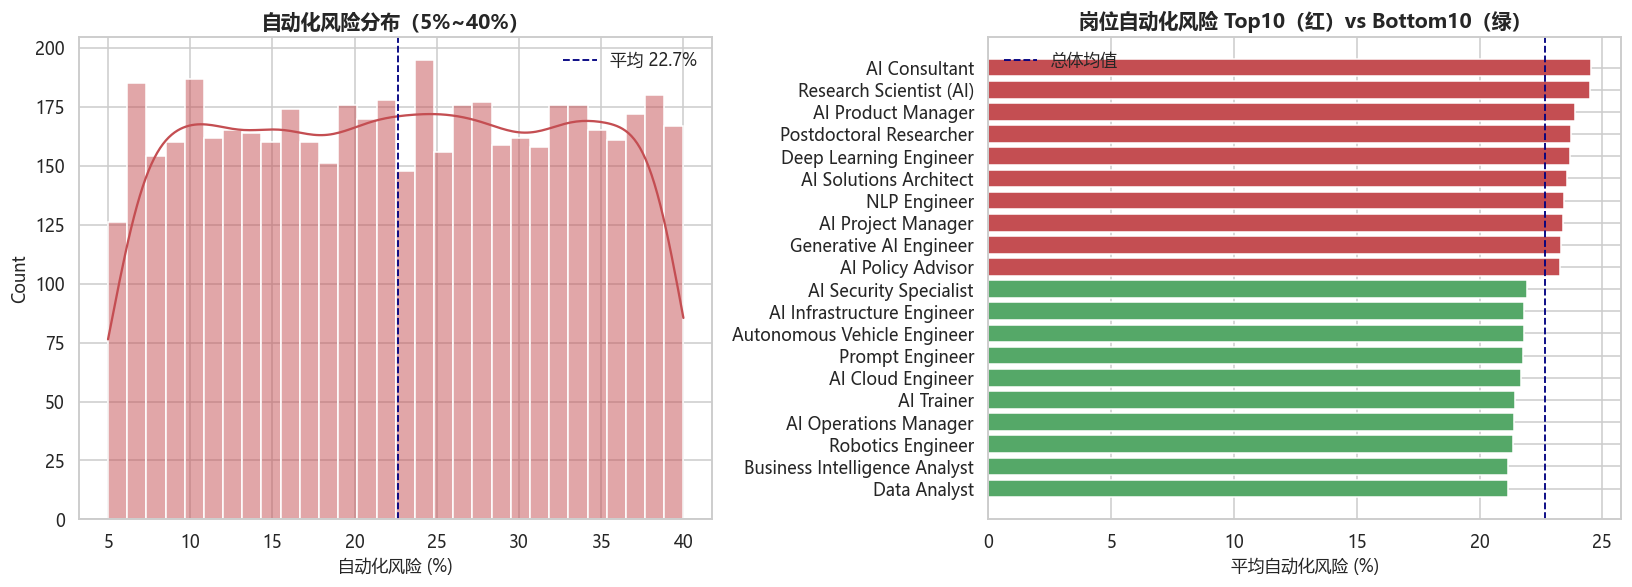

· 整体风险均值 22.7%，范围 5%~40%，未出现超高风险岗位（>50%）
· 风险最高：AI Consultant（24.6%）；最低：Data Analyst（21.2%）
· 高/低风险岗位差距约 3 个百分点，岗位间区分度有限（合成数据特征）


In [10]:
risk_by_role = (
    df.groupby("job_title")["automation_risk_pct"].mean().sort_values()
)
risk_low, risk_high = risk_by_role.head(10), risk_by_role.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.histplot(df, x="automation_risk_pct", bins=30, kde=True, ax=axes[0], color="#C44E52")
axes[0].axvline(df["automation_risk_pct"].mean(), color="navy", ls="--", lw=1.2,
                label=f"平均 {df['automation_risk_pct'].mean():.1f}%")
axes[0].set_title("自动化风险分布（5%~40%）"); axes[0].set_xlabel("自动化风险 (%)"); axes[0].legend()

combined = pd.concat([risk_low, risk_high])
colors = ["#55A868"] * len(risk_low) + ["#C44E52"] * len(risk_high)
axes[1].barh(combined.index, combined.values, color=colors)
axes[1].axvline(df["automation_risk_pct"].mean(), color="navy", ls="--", lw=1.2, label="总体均值")
axes[1].set_title("岗位自动化风险 Top10（红）vs Bottom10（绿）")
axes[1].set_xlabel("平均自动化风险 (%)"); axes[1].legend()

plt.tight_layout(); plt.show()

insights(
    f"整体风险均值 {df['automation_risk_pct'].mean():.1f}%，范围 5%~40%，未出现超高风险岗位（>50%）",
    f"风险最高：{risk_high.index[-1]}（{risk_high.iloc[-1]:.1f}%）；最低：{risk_low.index[0]}（{risk_low.iloc[0]:.1f}%）",
    f"高/低风险岗位差距约 {risk_high.iloc[-1] - risk_low.iloc[0]:.0f} 个百分点，岗位间区分度有限（合成数据特征）",
)

## 8. Job satisfaction patterns —— 工作满意度模式

**管道**：`groupby(experience_level)` 聚合满意度与工作生活平衡；`corr()` 计算满意度与相关因素的相关系数。

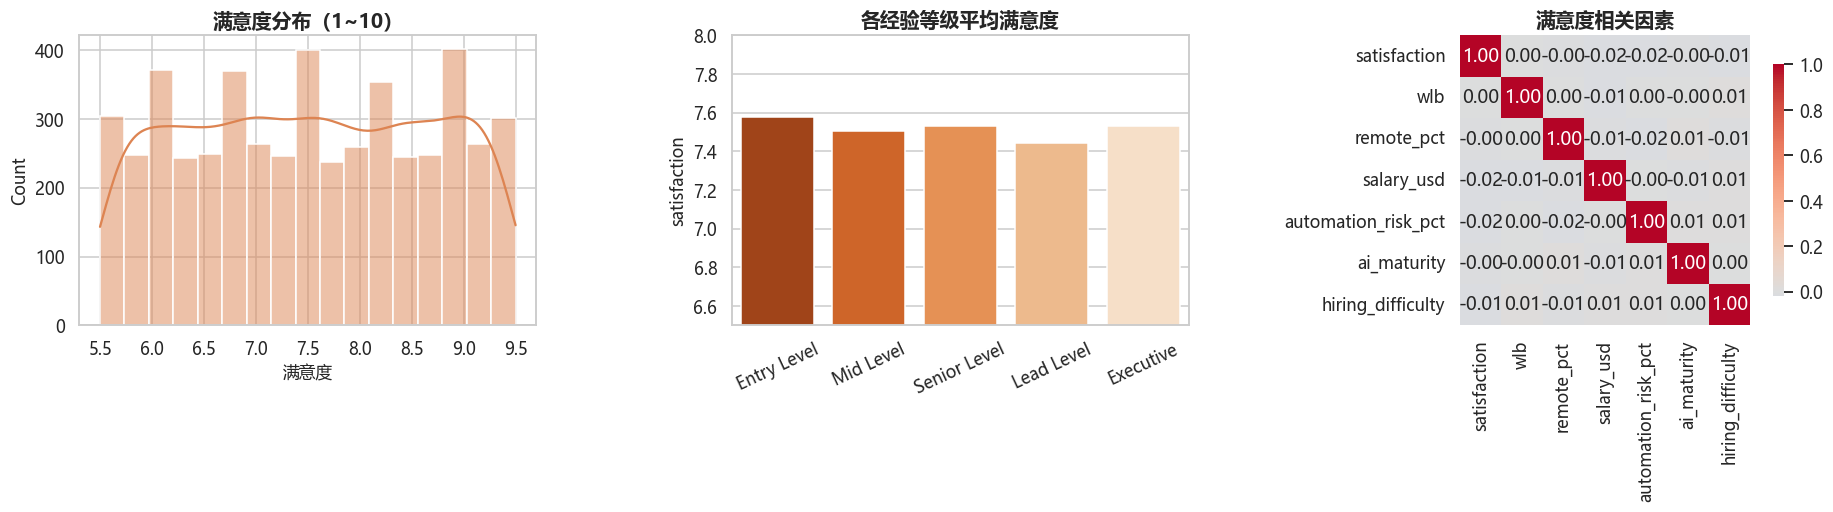

· 满意度均值 7.51/10，集中于 5.7~9.3，整体偏正面
· 各经验等级满意度差异很小（7.44~7.58）
· 满意度与工作生活平衡 r=0.00、与薪资 r=-0.02，各因素线性相关极弱 —— 满意度在本数据集中接近随机生成（合成数据特征）


In [11]:
sat_by_level = (
    df.groupby("experience_level")
      .agg(satisfaction=("satisfaction", "mean"), wlb=("wlb", "mean"))
      .reindex(EXP_ORDER)
)
corr_cols = ["satisfaction", "wlb", "remote_pct", "salary_usd",
             "automation_risk_pct", "ai_maturity", "hiring_difficulty"]
corr = df[corr_cols].corr()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.histplot(df, x="satisfaction", bins=17, kde=True, ax=axes[0], color="#DD8452")
axes[0].set_title("满意度分布（1~10）"); axes[0].set_xlabel("满意度")

sns.barplot(x=sat_by_level.index, y=sat_by_level["satisfaction"], hue=sat_by_level.index,
            palette="Oranges_r", legend=False, ax=axes[1])
axes[1].set_ylim(6.5, 8)
axes[1].set_title("各经验等级平均满意度"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=25)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": 0.8}, ax=axes[2])
axes[2].set_title("满意度相关因素")

plt.tight_layout(); plt.show()

sat_wlb = corr.loc["satisfaction", "wlb"]
sat_salary = corr.loc["satisfaction", "salary_usd"]
insights(
    f"满意度均值 {df['satisfaction'].mean():.2f}/10，集中于 {df['satisfaction'].quantile(0.05):.1f}~{df['satisfaction'].quantile(0.95):.1f}，整体偏正面",
    f"各经验等级满意度差异很小（{sat_by_level['satisfaction'].min():.2f}~{sat_by_level['satisfaction'].max():.2f}）",
    f"满意度与工作生活平衡 r={sat_wlb:.2f}、与薪资 r={sat_salary:.2f}，各因素线性相关极弱 —— 满意度在本数据集中接近随机生成（合成数据特征）",
)

## EDA 小结

| 维度 | 关键发现 |
|---|---|
| 岗位构成 | 36 类岗位 × 8 大专业方向，数量高度均衡，无明显头部集中 |
| 薪资 | 均值约 $158K、中位数约 $142K，右偏长尾（最高 $718K） |
| 经验 | 0~20 年均匀分布，Senior + Mid 合计超 6 成 |
| 地理 | 欧洲约 45%、亚洲约 29% 为两大聚集地；岗位分散在 50 国 |
| 行业 | 28 个行业均衡分布，Banking 岗位最多 |
| 远程 | 平均远程比例约 58%，64% 岗位支持 WFH，行业差异平缓 |
| 自动化风险 | 均值约 23%（5%~40%），岗位间梯度平缓 |
| 满意度 | 均值 7.5/10，与薪资/工作生活平衡等特征的线性相关均极弱（合成数据随机生成） |

**数据质量提示**：`Posted_Date` 存在 2026~2039 的未来日期；经验等级与实际年限一致性较弱 —— 该数据集为模拟/合成数据，结论侧重方法论演示，不宜直接用于真实市场决策。